# 4장 word2vec 속도 개선 — 이상의 『날개』로 CBOW 학습하기

제공된 **`word2vec_korean.ipynb`의 19개 셀을 기반으로, 김소월 시 데이터만 이상의 『날개』 한 작품으로 교체**한 실습입니다.
원본의 `common.korean.tokenize`, `CBOW`, `Trainer`, `Adam`, `create_contexts_target`,
`most_similar`, `analogy`를 그대로 가져와 실행합니다. 모델이나 평가 함수를 새로 구현하지 않습니다.

- 데이터는 『날개』의 한국어 본문 전체 1편입니다. 다른 작품과 합치거나 본문을 잘라내지 않았습니다.
- `min_count=3`, `window_size=3`, `hidden_size=100`, `batch_size=100`, `max_epoch=30`은 원본과 같습니다.
- 전처리·학습 셀은 원본 코드 그대로이며, 평가에서는 검색할 단어만 작품에 맞게 바꿨습니다.
  SVD 시각화도 원본처럼 `U[:, 0]`, `U[:, 1]`을 사용합니다.
- 파일 두 개를 유지하기 위해 **환경 준비 셀의 경로만 조정**했습니다.
  교재 코드는 임시 폴더로 내려받아 수정 없이 사용하고, 원본의 pickle 저장 셀도 그 임시 폴더에서 실행합니다.

### 실행 방법

1. 이 노트북과 `korean_literature.txt`를 같은 폴더에 두고 위에서부터 실행합니다.
   Colab에서는 노트북을 열고 왼쪽 파일 패널에 데이터 파일을 업로드합니다.
2. 첫 실행에는 교재 코드를 받기 위한 인터넷 연결과 `git`이 필요합니다.
   Python 환경에는 `numpy`, `matplotlib`이 필요합니다. Colab에는 기본 제공됩니다.
3. 내려받는 코드는 [수업 저장소의 고정 커밋](https://github.com/ssuai/deep_learning_from_scratch2/tree/324aed740260ba9581ebba6fe932c7cb100ea5a0)입니다.
   처음 받은 뒤에는 같은 임시 폴더의 코드를 재사용합니다.
4. 학습 로그와 그래프, 평가 출력은 이 노트북에 저장됩니다. `HW`의 제출 파일은 두 개만 유지됩니다.

검증 환경: Python 3.12, NumPy 1.26.4, Matplotlib 3.9.4.
원본처럼 난수 시드를 고정하지 않으므로 다시 학습하면 손실과 검색 결과가 달라질 수 있습니다.

In [1]:
# 원본과 같은 교재 모듈을 사용한다. HW에 추가 파일이 생기지 않도록 임시 폴더에 준비한다.
def is_colab():
    try:
        import google.colab
        return True
    except ImportError:
        return False

import sys
import os
import subprocess
import tempfile
from pathlib import Path

# 작업 폴더를 ch04로 옮기기 전에, 동봉한 데이터의 절대 경로를 기억한다.
# 같은 커널에서 첫 셀을 다시 실행해도 처음 확인한 경로를 유지한다.
if 'DATA_PATH' not in globals() or not DATA_PATH.is_file():
    candidates = [Path('korean_literature.txt'), Path('HW/korean_literature.txt'),
                  Path('/content/korean_literature.txt')]
    DATA_PATH = next((p.resolve() for p in candidates if p.is_file()), None)
    if DATA_PATH is None:
        raise FileNotFoundError('korean_literature.txt를 노트북과 같은 폴더에 놓아 주세요.')

TEXTBOOK_COMMIT = '324aed740260ba9581ebba6fe932c7cb100ea5a0'
TEXTBOOK_ROOT = Path(tempfile.gettempdir()) / ('word2vec-textbook-' + TEXTBOOK_COMMIT[:12])
if not (TEXTBOOK_ROOT / '.git').is_dir():
    subprocess.run(['git', 'clone', '--filter=blob:none', '--sparse', '--no-checkout',
                    'https://github.com/ssuai/deep_learning_from_scratch2.git',
                    str(TEXTBOOK_ROOT)], check=True)
    subprocess.run(['git', '-C', str(TEXTBOOK_ROOT), 'sparse-checkout',
                    'set', 'common', 'ch04'], check=True)
    subprocess.run(['git', '-C', str(TEXTBOOK_ROOT), 'checkout', '--detach',
                    TEXTBOOK_COMMIT], check=True)
actual_commit = subprocess.check_output(
    ['git', '-C', str(TEXTBOOK_ROOT), 'rev-parse', 'HEAD'], text=True).strip()
if actual_commit != TEXTBOOK_COMMIT:
    raise RuntimeError('교재 코드의 버전이 다릅니다. 임시 저장소를 확인하세요.')

if is_colab():
    subprocess.run(['apt-get', '-qq', 'install', 'fonts-nanum'],
                   check=True, stdout=subprocess.DEVNULL)
    import matplotlib.font_manager as fm
    fm._load_fontmanager(try_read_cache=False)

os.chdir(TEXTBOOK_ROOT / 'ch04')  # 원본과 같은 ch04 실행 환경
sys.path.insert(0, str(TEXTBOOK_ROOT))
sys.path.insert(0, str(TEXTBOOK_ROOT / 'ch04'))
print('교재 코드:', TEXTBOOK_COMMIT)
print('데이터:', DATA_PATH)
print('실행 및 임시 모델 저장 폴더:', Path.cwd())

교재 코드: 324aed740260ba9581ebba6fe932c7cb100ea5a0
데이터: /Users/parkdongjun/Desktop/3-2/딥러닝/HW/korean_literature.txt
실행 및 임시 모델 저장 폴더: /private/var/folders/k8/7vktmcz9597_lk6lp9g6t3_80000gn/T/word2vec-textbook-324aed740260/ch04


## 말뭉치: 이상 『날개』 1편

`korean_literature.txt`에는 이상의 소설 **『날개』 한 작품의 한국어 본문 전체**가 들어 있습니다.
[한국어 위키문헌의 고정 판본](https://ko.wikisource.org/w/index.php?oldid=221326)에서
2026년 11월 17일 수집했습니다. 작품은 1936년 《조광》에 발표되었으며, 해당 문서는 `PD-old-70`을 표시합니다.
[문서의 기여 이력](https://ko.wikisource.org/w/index.php?title=날개&action=history)도 확인할 수 있습니다.

MediaWiki API의 `action=parse&oldid=221326&prop=text|wikitext&format=json` 응답에서
작품의 첫 문단부터 라이선스 제목 직전까지의 본문을 추출했습니다.
소개·메뉴·라이선스는 제외하고 문단 내 공백만 정리했으며,
공백 정리 후 본문 전체가 원문 위키텍스트와 일치하는지 확인했습니다.
다른 작품, 해설, 번역문, 생성 문장은 포함하지 않습니다.

본문은 **167문단·22,184자·9,023토큰**으로 김소월 예제의 13,475토큰보다 짧습니다.
글자 수는 제목과 줄바꿈을 제외하고 공백을 포함한 값입니다.
파일 형식은 원본 예제처럼 `## 제목 | 저자` 다음에 본문 한 문단이 한 줄씩 이어집니다.
원본 코드와 비교하기 쉽도록 본문을 담는 변수 이름 `poems`도 유지합니다.

In [2]:
poems = []  # [(제목, [행, 행, ...]), ...]
with open(DATA_PATH, encoding='utf-8') as f:
    for line in f:
        line = line.strip()
        if line.startswith('## '):
            title = line[3:].split('|')[0].strip()
            poems.append((title, []))
        elif line:
            poems[-1][1].append(line)

print('작품 %d편, %d행, %d글자' % (len(poems), sum(len(lines) for _, lines in poems),
                                 sum(len(l) for _, lines in poems for l in lines)))
print('제목:', ', '.join(title for title, _ in poems[:30]), '...')

작품 1편, 167행, 22184글자
제목: 날개 ...


In [3]:
def show_poem(title):
    for t, lines in poems:
        if t == title:
            print('[%s]' % t)
            print('\n'.join(lines))
            print()

show_poem('날개')

[날개]
‘박제가 되어 버린 천재’를 아시오? 나는 유쾌하오. 이런 때 연애까지가 유쾌하오.
육신이 흐느적흐느적하도록 피로했을 때만 정신이 은화처럼 맑소. 니코틴이 내 횟배 앓는 뱃속으로 스미면 머릿속에 으레 백지가 준비되는 법이오. 그 위에다 나는 위트와 패러독스를 바둑 포석처럼 늘어놓소. 가증할 상식의 병이오.
나는 또 여인과 생활을 설계하오. 연애기법에마저 서먹서먹해진 지성의 극치를 흘깃 좀 들여다본 일이 있는, 말하자면 일종의 정신분일자말이오. 이런 여인의 반 — 그것은 온갖 것의 반이오. — 만을 영수하는 생활을 설계한다는 말이오. 그런 생활 속에 한 발만 들여놓고 흡사 두 개의 태양처럼 마주 쳐다보면서 낄낄거리는 것이오. 나는 아마 어지간히 인생의 제행이 싱거워서 견딜 수가 없게끔 되고 그만둔 모양이오. 굿바이.
굿바이. 그대는 이따금 그대가 제일 싫어하는 음식을 탐식하는 아이러니를 실천해 보는 것도 좋을 것 같소. 위트와 패러독스와…….
그대 자신을 위조하는 것도 할 만한 일이오. 그대의 작품은 한 번도 본 일이 없는 기성품에 의하여 차라리 경편하고 고매하리다.
19세기는 될 수 있거든 봉쇄하여 버리오. 도스토옙스키 정신이란 자칫하면 낭비일 것 같소. 위고를 불란서의 빵 한 조각이라고는 누가 그랬는지 지언인 듯싶소. 그러나 인생 혹은 그 모형에 있어서 ‘디테일’ 때문에 속는다거나 해서야 되겠소?
화를 보지 마오. 부디 그대께 고하는 것이니…….
“테이프가 끊어지면 피가 나오. 생채기도 머지않아 완치될 줄 믿소. 굿바이.” 감정은 어떤 ‘포즈’. (그 ‘포즈’의 원소만을 지적하는 것이 아닌지 나도 모르겠소.) 그 포우즈가 부동자세에까지 고도화할 때 감정은 딱 공급을 정지합네다.
나는 내 비범한 발육을 회고하여 세상을 보는 안목을 규정하였소.
여왕봉과 미망인— 세상의 하고 많은 여인이 본질적으로 이미 미망인이 아닌 이가 있으리까? 아니, 여인의 전부가 그 일상에 있어서 개개 ‘미망인’이라는 내 논리가 뜻밖에도 여성에 대한 모독이 되오? 굿바이.
그 3

## 한글 토크나이저

영어는 공백으로 단어를 나누면 되지만, 한글은 `꽃이`, `꽃을`, `꽃은`처럼 명사 뒤에 조사가 붙어서
공백으로만 나누면 같은 단어가 여러 어휘로 흩어집니다.
`common/korean.py`의 `tokenize()`는 형태소 분석기 없이 간단한 규칙으로 어절 끝의 조사를 떼어내어
`꽃`, `-이`처럼 돌려줍니다(떼어낸 조사는 앞에 `-`를 붙여 구분합니다).
완벽하지는 않지만(예: `여름없이` → `여름없`, `-이`) 교재 코드로 한글을 실습해 보기에는 충분합니다.

In [4]:
from common.korean import tokenize

for line in poems[0][1][:4]:          # 작품(날개)의 앞 네 문단
    print(line, '->', tokenize(line))
print()
print(tokenize('산에는 꽃 피네 꽃이 피네 갈 봄 여름없이 꽃이 피네'))

‘박제가 되어 버린 천재’를 아시오? 나는 유쾌하오. 이런 때 연애까지가 유쾌하오. -> ['‘', '박제', '-가', '되어', '버린', '천재', '’', '를', '아시오', '?', '나', '-는', '유쾌하오', '.', '이런', '때', '연애까지', '-가', '유쾌하오', '.']
육신이 흐느적흐느적하도록 피로했을 때만 정신이 은화처럼 맑소. 니코틴이 내 횟배 앓는 뱃속으로 스미면 머릿속에 으레 백지가 준비되는 법이오. 그 위에다 나는 위트와 패러독스를 바둑 포석처럼 늘어놓소. 가증할 상식의 병이오. -> ['육신', '-이', '흐느적흐느적하도록', '피로했', '-을', '때', '-만', '정신', '-이', '은화', '-처럼', '맑소', '.', '니코틴', '-이', '내', '횟배', '앓는', '뱃속', '-으로', '스미면', '머릿속', '-에', '으레', '백지', '-가', '준비되는', '법이오', '.', '그', '위에다', '나', '-는', '위트', '-와', '패러독스', '-를', '바둑', '포석', '-처럼', '늘어놓소', '.', '가증할', '상식', '-의', '병이오', '.']
나는 또 여인과 생활을 설계하오. 연애기법에마저 서먹서먹해진 지성의 극치를 흘깃 좀 들여다본 일이 있는, 말하자면 일종의 정신분일자말이오. 이런 여인의 반 — 그것은 온갖 것의 반이오. — 만을 영수하는 생활을 설계한다는 말이오. 그런 생활 속에 한 발만 들여놓고 흡사 두 개의 태양처럼 마주 쳐다보면서 낄낄거리는 것이오. 나는 아마 어지간히 인생의 제행이 싱거워서 견딜 수가 없게끔 되고 그만둔 모양이오. 굿바이. -> ['나', '-는', '또', '여인', '-과', '생활', '-을', '설계하오', '.', '연애기법에', '-마저', '서먹서먹해진', '지성', '-의', '극치', '-를', '흘깃', '좀', '들여다본', '일', '-이', '있는', ',', '말하자면', '일종', '-의', '정

## 말뭉치를 단어 ID로 바꾸기

아래 코드는 원본 노트북과 같습니다. `tokenize()`로 얻은 토큰에 ID를 부여하고,
`min_count=3`보다 적게 등장한 단어를 `<unk>`로 바꿉니다.
『날개』는 약 9천 토큰의 작은 말뭉치이며, 희귀어를 합치면 어휘는 2,516개에서 438개로 줄고
전체 토큰의 약 26.5%가 `<unk>`가 됩니다.
문장부호와 조사도 원본처럼 학습에 포함합니다.

In [5]:
import collections
import numpy as np

min_count = 3  # 이보다 적게 나온 단어는 <unk>로 바꾼다

words = tokenize(' '.join(l for _, lines in poems for l in lines))
counts = collections.Counter(words)
words = [w if counts[w] >= min_count else '<unk>' for w in words]

word_to_id = {}
id_to_word = {}
for word in words:
    if word not in word_to_id:
        new_id = len(word_to_id)
        word_to_id[word] = new_id
        id_to_word[new_id] = word
corpus = np.array([word_to_id[w] for w in words])
vocab_size = len(word_to_id)

print('말뭉치 크기:', len(corpus))
print('전체 어휘 수: %d  ->  min_count=%d 적용 후: %d' % (len(counts), min_count, vocab_size))
print('<unk> 비율: %.1f%%' % (100 * np.mean(corpus == word_to_id['<unk>'])))
print('자주 나온 단어:', [w for w, _ in collections.Counter(words).most_common(40) if w != '<unk>'])

말뭉치 크기: 9023
전체 어휘 수: 2516  ->  min_count=3 적용 후: 438
<unk> 비율: 26.5%
자주 나온 단어: ['.', '-는', '-을', '나', '-이', '-가', '아내', '내', '-에', '-를', '것', '-의', '-도', '-은', '-나', '그', '-으로', ',', '그러', '방', '한', '것이다', '-만', '이', '-로', '-에서', '돈', '그것', '?', '-처럼', '없다', '좀', '속', '또', '이불', '수', '-에게', '…', '-와']


## 4.3.2 CBOW 모델 학습

아래 학습 셀은 제공된 `word2vec_korean.ipynb`와 **코드·하이퍼파라미터 모두 동일**합니다.
바뀐 것은 위에서 만든 말뭉치의 내용뿐입니다.
`cbow.py`의 CBOW와 `common.trainer.Trainer`, `common.optimizer.Adam`을 수정 없이 사용합니다.
네거티브 샘플링은 교재 모델 내부의 설정(오답 5개, 빈도 지수 0.75)을 그대로 따릅니다.

원본의 `eval_interval`을 유지하므로 로그는 각 에폭의 첫 반복에서 출력됩니다.
첫 출력은 첫 배치 손실이고 이후 출력도 에폭 전체 평균과 정확히 일치하지 않습니다.
아래 pickle 저장 셀도 원본과 같으며 파일 이름만 작품에 맞게 바꿉니다.
저장 위치는 첫 셀에서 준비한 임시 `ch04` 폴더여서 `HW`에 세 번째 파일을 만들지 않습니다.

| 에폭 1 |  반복 1 / 90 | 시간 0[s] | 손실 4.16
| 에폭 2 |  반복 1 / 90 | 시간 0[s] | 손실 3.82
| 에폭 3 |  반복 1 / 90 | 시간 0[s] | 손실 2.75
| 에폭 4 |  반복 1 / 90 | 시간 1[s] | 손실 2.54
| 에폭 5 |  반복 1 / 90 | 시간 1[s] | 손실 2.51
| 에폭 6 |  반복 1 / 90 | 시간 2[s] | 손실 2.51
| 에폭 7 |  반복 1 / 90 | 시간 2[s] | 손실 2.50
| 에폭 8 |  반복 1 / 90 | 시간 3[s] | 손실 2.50
| 에폭 9 |  반복 1 / 90 | 시간 3[s] | 손실 2.50
| 에폭 10 |  반복 1 / 90 | 시간 4[s] | 손실 2.49
| 에폭 11 |  반복 1 / 90 | 시간 4[s] | 손실 2.48
| 에폭 12 |  반복 1 / 90 | 시간 4[s] | 손실 2.48
| 에폭 13 |  반복 1 / 90 | 시간 5[s] | 손실 2.46
| 에폭 14 |  반복 1 / 90 | 시간 5[s] | 손실 2.46
| 에폭 15 |  반복 1 / 90 | 시간 6[s] | 손실 2.44
| 에폭 16 |  반복 1 / 90 | 시간 6[s] | 손실 2.41
| 에폭 17 |  반복 1 / 90 | 시간 7[s] | 손실 2.39
| 에폭 18 |  반복 1 / 90 | 시간 7[s] | 손실 2.37
| 에폭 19 |  반복 1 / 90 | 시간 8[s] | 손실 2.33
| 에폭 20 |  반복 1 / 90 | 시간 8[s] | 손실 2.30
| 에폭 21 |  반복 1 / 90 | 시간 8[s] | 손실 2.27
| 에폭 22 |  반복 1 / 90 | 시간 9[s] | 손실 2.23
| 에폭 23 |  반복 1 / 90 | 시간 9[s] | 손실 2.21
| 에폭 24 |  반복 1 / 90 | 시간 10[s] | 손실 2.18
| 에폭 25 |  반복 1 / 90 | 시

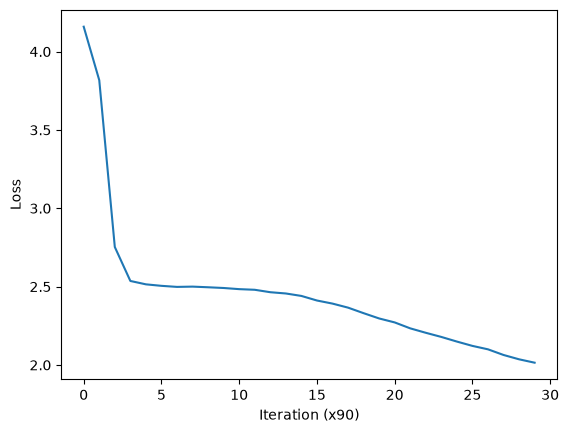

In [6]:
from common.trainer import Trainer
from common.optimizer import Adam
from common.util import create_contexts_target
from cbow import CBOW
# from skip_gram import SkipGram

# 하이퍼파라미터 설정
window_size = 3
hidden_size = 100
batch_size = 100
max_epoch = 30

contexts, target = create_contexts_target(corpus, window_size)

# 모델 등 생성
model = CBOW(vocab_size, hidden_size, window_size, corpus)
# model = SkipGram(vocab_size, hidden_size, window_size, corpus)
optimizer = Adam()
trainer = Trainer(model, optimizer)

# 학습 시작
trainer.fit(contexts, target, max_epoch, batch_size, eval_interval=len(corpus) // batch_size)  # 에폭마다 손실 출력
trainer.plot()

In [7]:
import pickle

# 나중에 사용할 수 있도록 필요한 데이터 저장(eval_korean.py에서 pkl_file을 바꾸면 읽을 수 있다)
params = {}
params['word_vecs'] = model.word_vecs.astype(np.float16)
params['word_to_id'] = word_to_id
params['id_to_word'] = id_to_word
with open('cbow_params_nalgae.pkl', 'wb') as f:
    pickle.dump(params, f, -1)

## 4.3.3 CBOW 모델 평가

교재 `eval.py`의 `most_similar()`를 그대로 사용합니다. 『날개』에 나오는 단어들로 질의합니다.
원본처럼 조사·문장부호·`<unk>`를 결과에서 별도로 걸러내지 않습니다.
`<unk>`는 등장 횟수가 적어 통합된 단어를 뜻합니다.
작품 제목인 `날개`도 토큰 빈도가 2여서 `min_count=3` 적용 후에는 검색할 수 없습니다.

In [8]:
from common.util import most_similar, analogy

word_vecs = model.word_vecs
querys = ['아내', '방', '돈', '이불', '잠', '외출', '낮', '밤', '아스피린', '아달린', '날개']
for query in querys:
    most_similar(query, word_to_id, id_to_word, word_vecs, top=5)


[query] 아내
 체취: 0.8596318960189819
 남자: 0.828295111656189
 아니: 0.7990381717681885
 여인: 0.7846798896789551
 장지: 0.779430091381073

[query] 방
 가서: 0.8055766820907593
 화장대: 0.7954249382019043
 내: 0.7795946598052979
 열고: 0.7740407586097717
 들어갔다: 0.7644857168197632

[query] 돈
 오: 0.898155927658081
 쓰는: 0.8319054841995239
 놓고: 0.8196531534194946
 기쁨: 0.8187777996063232
 남은: 0.8093909025192261

[query] 이불
 꾸지람: 0.8318712711334229
 또: 0.7901238203048706
 쓰고: 0.7862628698348999
 벌써: 0.7592344284057617
 이렇게: 0.7539042234420776

[query] 잠
 드는: 0.8691784739494324
 짓: 0.8237568736076355
 낮잠: 0.7982163429260254
 집: 0.7874315977096558
 오는: 0.7726351022720337

[query] 외출
 드디어: 0.8540082573890686
 하면: 0.8384277820587158
 확실히: 0.8239551186561584
 다시: 0.8185009956359863
 나왔다: 0.8146381378173828

[query] 낮
 밤: 0.8653087019920349
 오늘: 0.7025355696678162
 잤다: 0.6308732032775879
 -이나: 0.6024875044822693
 어느덧: 0.6015578508377075

[query] 밤
 낮: 0.8653087019920349
 오늘: 0.7497631907463074
 외출할: 0.6983636617660

유추도 원본의 `analogy()`로 실행합니다. 약 9천 토큰으로 학습한 벡터여서 결과는 참고만 합니다.
작품 속 공간 관계인 `아내:아랫방 = 나:?`를 시도하지만, 기대 단어 `윗방`은 빈도가 2여서 어휘에서 제외되었습니다.
두 번째 `낮:밤 = 외출:?`는 낮과 밤의 차이 방향을 외출 벡터에 적용하는 탐색이며 정해진 정답은 없습니다.

원본 함수는 유추 벡터만 정규화하고 후보 벡터와 내적합니다.
따라서 출력 점수는 코사인 유사도가 아니며 1을 넘을 수 있습니다. 이 계산도 수정하지 않았습니다.

In [9]:
analogy('아내', '아랫방', '나', word_to_id, id_to_word, word_vecs)   # 아내:아랫방 = 나:?
analogy('낮', '밤', '외출', word_to_id, id_to_word, word_vecs)   # 낮:밤 = 외출:?


[analogy] 아내:아랫방 = 나:?
 그러: 3.5467958450317383
 없다: 2.687472105026245
 것이다: 2.6468276977539062
 내게: 2.5044970512390137
 있었다: 2.5035271644592285

[analogy] 낮:밤 = 외출:?
 돈: 3.2212486267089844
 이불: 3.0235257148742676
 -는: 2.716438055038452
 꾸지람: 2.648966073989868
 화장대: 2.455151319503784


## 단어 벡터 2차원 시각화

아래 코드는 그래프 제목만 바꾸고 원본의 SVD 시각화를 그대로 수행합니다.
빈도가 높은 단어 중 조사·문장부호·`<unk>`를 제외한 한글 토큰을 고릅니다.
품사 분석을 하지 않으므로 명사만 포함되는 것은 아닙니다.
평균을 뺀 벡터에 SVD를 적용한 후 원본처럼 `U[:, 0]`, `U[:, 1]`을 좌표로 표시합니다.
한글 폰트는 원본의 `set_korean_font()`로 설정합니다.

matplotlib 한글 폰트: AppleGothic


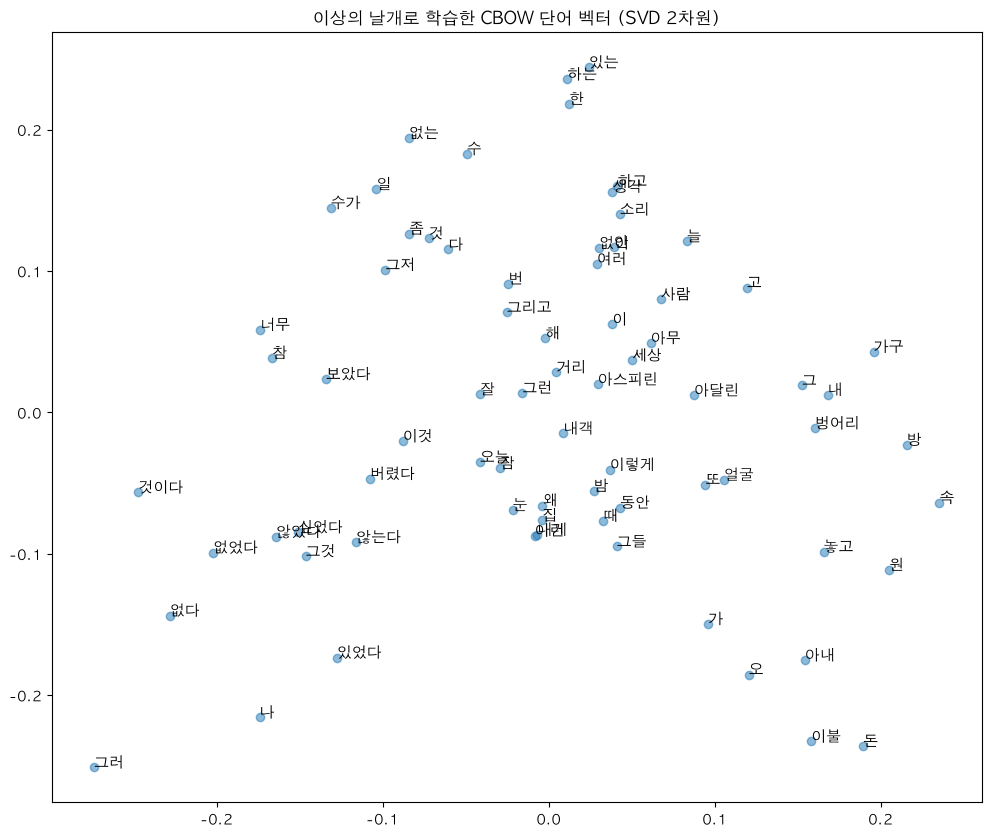

In [10]:
import matplotlib.pyplot as plt
from common.korean import set_korean_font, JOSA_MARK

set_korean_font()

# 자주 나온 단어 중 조사(-로 시작), 문장부호, <unk>를 뺀 것만 고른다
freq = collections.Counter(words)
show_words = [w for w, c in freq.most_common(120)
              if c >= 10 and w != '<unk>' and not w.startswith(JOSA_MARK) and ('가' <= w[0] <= '힣')]

W = np.array([word_vecs[word_to_id[w]] for w in show_words], dtype='f')
W = W - W.mean(axis=0)
U, S, V = np.linalg.svd(W)

plt.figure(figsize=(12, 10))
for i, word in enumerate(show_words):
    plt.annotate(word, (U[i, 0], U[i, 1]), fontsize=11)
plt.scatter(U[:, 0], U[:, 1], alpha=0.5)
plt.title('이상의 날개로 학습한 CBOW 단어 벡터 (SVD 2차원)')
plt.show()

## 결과 해석과 더 해 볼 것

이 실험은 한 작품 전체를 이용한 소규모 Word2Vec 학습입니다.
학습 손실 감소가 별도 테스트 데이터의 정확도 향상을 의미하지는 않습니다.
유사 단어는 동의어뿐 아니라 같은 작품의 비슷한 문맥에서 쓰인 단어일 수 있습니다.
희귀어를 `<unk>`로 통합했기 때문에 작품에서 중요한 단어도 검색할 수 없을 수 있습니다.

* 같은 작품에서 `min_count`, `window_size`, `hidden_size`, `max_epoch`을 바꿔 결과를 비교할 수 있습니다.
  제출된 기본 실행은 원본과 같은 설정을 사용합니다.
* 코드 출처: [수업 저장소](https://github.com/ssuai/deep_learning_from_scratch2/tree/324aed740260ba9581ebba6fe932c7cb100ea5a0).
  교재 코드는 임시 저장소에 원본 그대로 내려받으며 저장소의 MIT 라이선스를 따릅니다.

### 이번에 저장된 실행 결과

- 원본 `Trainer`의 출력 손실은 처음 약 4.16에서 마지막 약 2.01로 내려갔습니다.
  로그의 출력 시점은 원본과 같으며, 에폭 전체 평균이나 검증 손실로 해석하지 않습니다.
- `낮`과 `밤`은 서로 가장 가까운 단어로 검색되었습니다(약 0.859).
  반의어도 비슷한 문맥에서 쓰이면 가깝게 학습될 수 있습니다.
- `아스피린`과 `아달린`도 서로 가장 가까웠고(약 0.842), `아내`에는 `남자`, `체취`가 상위에 나왔습니다.
  작품 내 문맥이 일부 반영된 결과입니다.
- `이불`의 결과에는 `-마다` 같은 조사도 나옵니다. 원본과 동일하게 검색 결과를 추가로 필터링하지 않았습니다.
- `날개`는 토큰 빈도 2로 어휘에서 제외되어 검색할 수 없었습니다.
  `아내:아랫방 = 나:?`도 기대한 공간 관계를 보여 주지 못했으며, 작은 말뭉치와 희귀어 처리의 한계를 확인했습니다.

위 해석은 저장된 실행 결과 기준입니다. 원본처럼 난수 시드를 고정하지 않아 재실행 시 결과는 달라집니다.
